# score de risco Transacional- Fraud Analytics
## objetivo

construir um modelo de machine Learning capaz de atribuir um score de risco para cada transação.
O score representará a probabilidade estimada de uma transação ser fraudulenta.
Piperline:
Dados -> Features -> Modelo -> Probabilidade -> Score -> Políticas de Risco

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score
)

pd.set_option('display.max_columns', None)
print("Ambiente preparado")


Ambiente preparado


## Gerando 5000 Transações Fictícias

In [54]:
np.random.seed(42)  # Para reproducibilidad
n = 5000

df=pd.DataFrame({
    'valor_transação': np.random.exponential(scale=250, size=n),
    'idade_conta_dias': np.random.randint(0, 2000, size=n),
    'ticket_medio_cliente': np.random.exponential(scale=180, size=n),
    'dispositivo_novo': np.random.binomial(1, 0.15, size=n),
    'compra_madrugada': np.random.binomial(1, 0.10, size=n),
    'risco_loja': np.random.uniform(0, 1, size=n),

})

df.head(10)


,valor_transação,idade_conta_dias,ticket_medio_cliente,dispositivo_novo,compra_madrugada,risco_loja
0,117.317022,1074,153.439693,0,0,0.280887
1,752.530358,1094,310.205882,0,0,0.462803
2,329.186423,479,5.217662,0,0,0.946839
3,228.235638,1583,179.379905,0,0,0.726941
4,42.406218,1042,77.426093,0,1,0.011877
5,42.399073,1797,62.326801,0,0,0.116507
6,14.959692,83,89.738561,0,0,0.923811
7,502.807716,1178,75.345263,1,0,0.848719
8,229.770538,564,321.338802,0,0,0.486164
9,307.812515,618,57.834861,1,0,0.616978


In [55]:
df['razao_valor_ticket'] = (
    df['valor_transação'] / (df['ticket_medio_cliente'] + 1)
    )

In [56]:
df['tentativas_24hs'] = np.random.poisson(lam=1.5, size=n)
df['razao_valor_ticket'] = (
    df['valor_transação'] / (df['ticket_medio_cliente'] + 1)
)

In [57]:
df[
    [
        'valor_transação',
        'ticket_medio_cliente',
    ]
].head(10)

,valor_transação,ticket_medio_cliente
0,117.317022,153.439693
1,752.530358,310.205882
2,329.186423,5.217662
3,228.235638,179.379905
4,42.406218,77.426093
5,42.399073,62.326801
6,14.959692,89.738561
7,502.807716,75.345263
8,229.770538,321.338802
9,307.812515,57.834861


## Criando Fraude Simulada


In [58]:
print(df.columns.tolist())

['valor_transação', 'idade_conta_dias', 'ticket_medio_cliente', 'dispositivo_novo', 'compra_madrugada', 'risco_loja', 'razao_valor_ticket', 'tentativas_24hs']


In [59]:
z = (
    -4.0
    + 0.003 * df['valor_transação']
    +0.50 * df['tentativas_24hs']
    +1.20 * df['dispositivo_novo']
    +1.0 * df['compra_madrugada']
    +1.5 * df['risco_loja']
    +0.15 * df['razao_valor_ticket'].clip(upper=10)
)

prob_fraude = 1 / (1 + np.exp(-z))
df['fraude'] = np.random.binomial(1, prob_fraude)

In [60]:
df['fraude'].value_counts(normalize=True)


fraude
0    0.6884
1    0.3116
Name: proportion, dtype: float64

## Explorando o Dataset

In [61]:
df.shape

(5000, 9)

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   valor_transação       5000 non-null   float64
 1   idade_conta_dias      5000 non-null   int32  
 2   ticket_medio_cliente  5000 non-null   float64
 3   dispositivo_novo      5000 non-null   int32  
 4   compra_madrugada      5000 non-null   int32  
 5   risco_loja            5000 non-null   float64
 6   razao_valor_ticket    5000 non-null   float64
 7   tentativas_24hs       5000 non-null   int32  
 8   fraude                5000 non-null   int32  
dtypes: float64(4), int32(5)
memory usage: 254.0 KB


In [63]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
valor_transação,5000.0,247.439534,246.762782,0.002909,69.883122,173.291109,344.681635,2043.111399
idade_conta_dias,5000.0,999.594000,570.641953,0.000000,511.750000,997.000000,1491.250000,1999.000000
ticket_medio_cliente,5000.0,180.489134,180.089269,0.033338,54.010003,125.519502,248.941723,1486.752163
dispositivo_novo,5000.0,0.146800,0.353942,0.000000,0.000000,0.000000,0.000000,1.000000
compra_madrugada,5000.0,0.106200,0.308124,0.000000,0.000000,0.000000,0.000000,1.000000
risco_loja,5000.0,0.503897,0.289616,0.000021,0.254452,0.506764,0.753378,0.999891
razao_valor_ticket,5000.0,6.545015,26.326107,0.000026,0.453038,1.355659,4.040328,627.849595
tentativas_24hs,5000.0,1.495000,1.212217,0.000000,1.000000,1.000000,2.000000,9.000000
fraude,5000.0,0.311600,0.463194,0.000000,0.000000,0.000000,1.000000,1.000000


## taxa de fraude

In [64]:
taxa_fraude = df['fraude'].mean()
print(f'Taxa de fraude: {taxa_fraude:.2%}')

Taxa de fraude: 31.16%


# Machine Learning

In [65]:
features = [
    'valor_transação',
    'idade_conta_dias',
    'ticket_medio_cliente',
    'dispositivo_novo',
    'compra_madrugada',
    'risco_loja',
    'tentativas_24hs',
    'razao_valor_ticket'
]

x = df[features]
y = df['fraude']

In [66]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: fraude, dtype: int32

## Train/Test Split

In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size=0.30,
      random_state=42,
      stratify=y
)     


In [68]:
print('Treino', X_train.shape)
print('Teste', X_test.shape)

Treino (3500, 8)
Teste (1500, 8)


# O primeiro Modelo de Risco

In [69]:
modelo = LogisticRegression(
    max_iter=2000)

modelo.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [70]:
y_pred = modelo.predict(X_test)
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.78      0.92      0.84      1033
           1       0.70      0.42      0.53       467

    accuracy                           0.76      1500
   macro avg       0.74      0.67      0.69      1500
weighted avg       0.75      0.76      0.74      1500



## o SCORE

In [71]:
score_risco = modelo.predict_proba(X_test)[:,1]

In [72]:
score_risco[:10]


array([0.26010388, 0.30013752, 0.0809064 , 0.15376085, 0.06318629,
       0.05547778, 0.09348027, 0.90621446, 0.428616  , 0.19716234])

In [73]:
score_risco = score_risco *1000
score_risco[:10]

array([260.10387773, 300.13752072,  80.90640374, 153.76084834,
        63.18628509,  55.47778108,  93.48026871, 906.21445755,
       428.61600146, 197.16233884])

## analizando as trasações

In [74]:
resultado = X_test.copy()
resultado['fraude_real'] = y_test
resultado['score_risco'] = score_risco

resultado.sort_values(
    'score_risco', ascending=False

).head(10)

,valor_transação,idade_conta_dias,ticket_medio_cliente,dispositivo_novo,compra_madrugada,risco_loja,tentativas_24hs,razao_valor_ticket,fraude_real,score_risco
531,2043.111399,36,49.329743,0,0,0.785771,6,40.594513,1,999.772629
2789,1315.703483,1679,1.451573,1,0,0.163824,1,536.677316,1,999.141168
4608,782.555354,684,0.246406,0,0,0.038868,2,627.849595,1,992.167224
1054,1545.548603,513,152.601016,1,0,0.321315,1,10.062099,1,987.003479
1638,1222.663741,1840,138.905652,0,0,0.648344,4,8.739202,1,980.363459
4462,1415.634376,460,220.005508,0,0,0.923983,2,6.405426,1,979.006967
2782,993.375276,225,242.129822,0,1,0.636645,4,4.085781,1,977.232723
1912,1402.186558,610,232.438117,0,1,0.446751,1,6.006674,1,973.909026
4850,994.241434,1435,23.091837,0,1,0.741245,2,41.268810,1,969.520160
1889,1201.208860,1563,26.045494,1,0,0.703157,0,44.414380,1,969.070311


## Distribuicao do Score

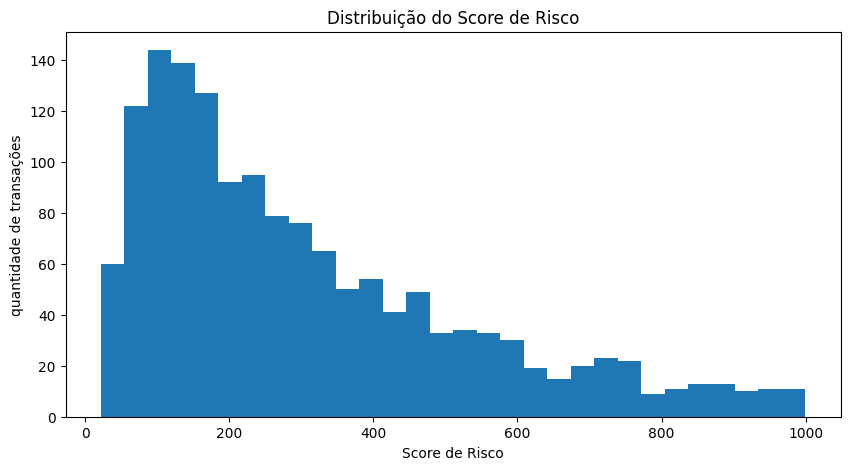

In [75]:
plt.figure(figsize=(10, 5))

plt.hist(
    resultado['score_risco'],
    bins=30,
)

plt.xlabel('Score de Risco')
plt.ylabel('quantidade de transações')
plt.title('Distribuição do Score de Risco')

plt.show()


## Criando Faixas de Risco


In [76]:
resultado["faixa_risco"] = pd.cut(
    resultado["score_risco"],
    bins=[0, 0.20, 0.50, 0.80, 1.00],
    labels=[
        "Baixo",
        "Médio",
        "Alto",
        "Muito Alto"
    ],
    include_lowest=True
)


In [77]:
resultado["faixa_risco"].value_counts(dropna=False)

faixa_risco
NaN           1500
Baixo            0
Médio            0
Alto             0
Muito Alto       0
Name: count, dtype: int64

In [78]:
analise_risco = (
    resultado
    .groupby('faixa_risco', observed=False)
    .agg(
        transacoes=('fraude_real', 'count'),
        fraudes=('fraude_real', 'sum'),
        taxa_fraude=('fraude_real', 'mean'),
        score_medio=('score_risco', 'mean')
       )
)

analise_risco


,transacoes,fraudes,taxa_fraude,score_medio
faixa_risco,,,,
Baixo,0,0,NaN,NaN
Médio,0,0,NaN,NaN
Alto,0,0,NaN,NaN
Muito Alto,0,0,NaN,NaN


In [79]:
resultado["score_risco"].describe()

count    1500.000000
mean      306.831411
std       226.260370
min        21.619806
25%       132.878972
50%       239.304163
75%       430.621599
max       999.772629
Name: score_risco, dtype: float64

In [80]:
resultado["score_risco"].head(10)

2595    260.103878
2581    300.137521
1087     80.906404
1352    153.760848
752      63.186285
332      55.477781
1288     93.480269
971     906.214458
4270    428.616001
4034    197.162339
Name: score_risco, dtype: float64

In [81]:
resultado = X_test.copy().reset_index(drop=True)

resultado["fraude_real"] = y_test.reset_index(drop=True)

resultado["score_risco"] = modelo.predict_proba(X_test)[:, 1]

resultado.head()

,valor_transação,idade_conta_dias,ticket_medio_cliente,dispositivo_novo,compra_madrugada,risco_loja,tentativas_24hs,razao_valor_ticket,fraude_real,score_risco
0,373.298627,1035,121.177934,0,0,0.437739,1,3.055369,0,0.260104
1,548.789609,1144,66.122932,0,0,0.381897,0,8.175889,0,0.300138
2,45.690597,1934,65.751250,0,0,0.639203,0,0.684491,0,0.080906
3,144.337270,1594,39.202665,0,0,0.501419,1,3.590241,0,0.153761
4,247.019232,1545,767.373983,0,0,0.481251,0,0.321483,0,0.063186


In [82]:
resultado["score_risco"].describe()

count    1500.000000
mean        0.306831
std         0.226260
min         0.021620
25%         0.132879
50%         0.239304
75%         0.430622
max         0.999773
Name: score_risco, dtype: float64

## A Partir de Qual SCORE considero uma transacao suspeita

In [83]:
y_test.value_counts()

fraude
0    1033
1     467
Name: count, dtype: int64

In [84]:
print(f'Fraudes: {y_test.sum()}')
print(f'Legitimas: {(y_test == 0).sum()}')
print(f'Taxa de fraude: {y_test.mean():.2%}')

Fraudes: 467
Legitimas: 1033
Taxa de fraude: 31.13%


## Threshod padrao = 0.50

In [87]:
modelo.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(1500,), dtype=int32)

In [88]:
threshold = 0.50

resultado['predicao_050'] =(
    resultado['score_risco'] >= threshold

).astype(int)

In [89]:
resultado[
    [
        'score_risco',
        'fraude_real',
        'predicao_050'
    ]
].head(10)


,score_risco,fraude_real,predicao_050
0,0.260104,0,0
1,0.300138,0,0
2,0.080906,0,0
3,0.153761,0,0
4,0.063186,0,0
5,0.055478,0,0
6,0.093480,0,0
7,0.906214,1,1
8,0.428616,0,0
9,0.197162,0,0


# Agora temos tres conceitos diferentes
score_risco    → probabilidade estimada
fraude_real    → o que realmente aconteceu
predicao_050   → decisão do modelo

## Matriz de Confusao

In [90]:
cm= confusion_matrix(
    
    resultado['fraude_real'],
    resultado['predicao_050']

)
cm

array([[948,  85],
       [269, 198]])

In [91]:
tn, fp, fn, tp = cm.ravel()

print(f"TN - Legítimas corretamente identificadas: {tn}")
print(f"FP - Legítimas classificadas como fraude: {fp}")
print(f"FN - Fraudes que escaparam: {fn}")
print(f"TP - Fraudes corretamente detectadas: {tp}")

TN - Legítimas corretamente identificadas: 948
FP - Legítimas classificadas como fraude: 85
FN - Fraudes que escaparam: 269
TP - Fraudes corretamente detectadas: 198


## Calculando a Accuracy

In [92]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    resultado['fraude_real'],
    resultado['predicao_050']
)
print(f"Acurácia: {accuracy:.2%}")


Acurácia: 76.40%


## Recall - quantas fraudes conseguimos capturar

In [93]:
from sklearn.metrics import recall_score

recall = recall_score(
    resultado['fraude_real'],
    resultado['predicao_050']
)
print(f'Recall: {recall:.2%}')

Recall: 42.40%


# Precision

In [94]:
from sklearn.metrics import precision_score

precision = precision_score(
    resultado['fraude_real'],
    resultado['predicao_050']
)
print(f'Precisão: {precision:.2%}')

Precisão: 69.96%


In [96]:
from sklearn.metrics import precision_score, recall_score

def avaliar_threshold(threshold):

    pred = (
        resultado["score_risco"] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        resultado["fraude_real"],
        pred
    ).ravel()

    precision = precision_score(
        resultado["fraude_real"],
        pred,
        zero_division=0
    )

    recall = recall_score(
        resultado["fraude_real"],
              pred
    )

    return {
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": precision,
        "recall": recall
    }

In [97]:
avaliar_threshold(0.50)


{'threshold': 0.5,
 'TP': np.int64(198),
 'FP': np.int64(85),
 'FN': np.int64(269),
 'TN': np.int64(948),
 'precision': 0.6996466431095406,
 'recall': 0.42398286937901497}

In [98]:
avaliar_threshold(0.30)

{'threshold': 0.3,
 'TP': np.int64(313),
 'FP': np.int64(284),
 'FN': np.int64(154),
 'TN': np.int64(749),
 'precision': 0.52428810720268,
 'recall': 0.6702355460385439}

In [99]:
avaliar_threshold(0.70)


{'threshold': 0.7,
 'TP': np.int64(112),
 'FP': np.int64(14),
 'FN': np.int64(355),
 'TN': np.int64(1019),
 'precision': 0.8888888888888888,
 'recall': 0.2398286937901499}

# comparar

In [100]:
thresholds = [
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80
]

comparacao = pd.DataFrame(
    [avaliar_threshold(t) for t in thresholds]
)

comparacao

,threshold,TP,FP,FN,TN,precision,recall
0,0.2,395,468,72,565,0.457706,0.845824
1,0.3,313,284,154,749,0.524288,0.670236
2,0.4,249,171,218,862,0.592857,0.533191
3,0.5,198,85,269,948,0.699647,0.423983
4,0.6,144,37,323,996,0.795580,0.308351
5,0.7,112,14,355,1019,0.888889,0.239829
6,0.8,64,7,403,1026,0.901408,0.137045


## Agora Vamos colocar o Dinheiro nesse problema de negocio

In [104]:
resultado.columns.tolist()

['valor_transação',
 'idade_conta_dias',
 'ticket_medio_cliente',
 'dispositivo_novo',
 'compra_madrugada',
 'risco_loja',
 'tentativas_24hs',
 'razao_valor_ticket',
 'fraude_real',
 'score_risco',
 'predicao_050']

In [106]:
def avaliar_threshold_negocio(threshold):

    temp = resultado.copy()

    temp["pred"] = (
        temp["score_risco"] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        temp["fraude_real"],
        temp["pred"]
    ).ravel()

    fraude_capturada = temp[
        (temp["fraude_real"] == 1) &
        (temp["pred"] == 1)
    ]["valor_transação"].sum()

    fraude_nao_detectada = temp[
        (temp["fraude_real"] == 1) &
        (temp["pred"] == 0)
    ]["valor_transação"].sum()

    return {
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": tp / (tp + fp) if (tp + fp) > 0 else 0,
        "recall": tp / (tp + fn) if (tp + fn) > 0 else 0,
        "fraude_capturada_R$": fraude_capturada,
        "fraude_perdida_R$": fraude_nao_detectada
    }

In [107]:
comparacao_negocio = pd.DataFrame(
    [
        avaliar_threshold_negocio(t)
        for t in thresholds
    ]
)

comparacao_negocio

,threshold,TP,FP,FN,TN,precision,recall,fraude_capturada_R$,fraude_perdida_R$
0,0.2,395,468,72,565,0.457706,0.845824,162828.229972,8660.939728
1,0.3,313,284,154,749,0.524288,0.670236,145648.764512,25840.405188
2,0.4,249,171,218,862,0.592857,0.533191,129648.956810,41840.212890
3,0.5,198,85,269,948,0.699647,0.423983,113611.436596,57877.733104
4,0.6,144,37,323,996,0.795580,0.308351,95641.292713,75847.876987
5,0.7,112,14,355,1019,0.888889,0.239829,80689.828458,90799.341242
6,0.8,64,7,403,1026,0.901408,0.137045,53683.137135,117806.032565


In [108]:
comparacao_negocio.style.format({
    "precision": "{:.2%}",
    "recall": "{:.2%}",
    "fraude_capturada_R$": "R$ {:,.2f}",
    "fraude_perdida_R$": "R$ {:,.2f}"
})

,threshold,TP,FP,FN,TN,precision,recall,fraude_capturada_R$,fraude_perdida_R$
0,0.200000,395,468,72,565,45.77%,84.58%,"R$ 162,828.23","R$ 8,660.94"
1,0.300000,313,284,154,749,52.43%,67.02%,"R$ 145,648.76","R$ 25,840.41"
2,0.400000,249,171,218,862,59.29%,53.32%,"R$ 129,648.96","R$ 41,840.21"
3,0.500000,198,85,269,948,69.96%,42.40%,"R$ 113,611.44","R$ 57,877.73"
4,0.600000,144,37,323,996,79.56%,30.84%,"R$ 95,641.29","R$ 75,847.88"
5,0.700000,112,14,355,1019,88.89%,23.98%,"R$ 80,689.83","R$ 90,799.34"
6,0.800000,64,7,403,1026,90.14%,13.70%,"R$ 53,683.14","R$ 117,806.03"


## Threshold + Acressentando o custo do falso positivo

In [111]:
custo_fp = 5

comparacao_negocio["custo_FP_R$"] = (
    comparacao_negocio["FP"] * custo_fp
)

comparacao_negocio["custo_total_R$"] = (
    comparacao_negocio["fraude_perdida_R$"]
    + comparacao_negocio["custo_FP_R$"]
)

In [113]:
comparacao_negocio[
    [
        "threshold",
        "TP",
        "FP",
        "FN",
        "precision",
        "recall",
        "fraude_capturada_R$",
        "fraude_perdida_R$",
        "custo_FP_R$",
        "custo_total_R$"
    ]
].style.format({
    "threshold": "{:.2f}",
    "precision": "{:.2%}",
    "recall": "{:.2%}",
    "fraude_capturada_R$": "R$ {:,.2f}",
    "fraude_perdida_R$": "R$ {:,.2f}",
    "custo_FP_R$": "R$ {:,.2f}",
    "custo_total_R$": "R$ {:,.2f}"
})

,threshold,TP,FP,FN,precision,recall,fraude_capturada_R$,fraude_perdida_R$,custo_FP_R$,custo_total_R$
0,0.20,395,468,72,45.77%,84.58%,"R$ 162,828.23","R$ 8,660.94","R$ 2,340.00","R$ 11,000.94"
1,0.30,313,284,154,52.43%,67.02%,"R$ 145,648.76","R$ 25,840.41","R$ 1,420.00","R$ 27,260.41"
2,0.40,249,171,218,59.29%,53.32%,"R$ 129,648.96","R$ 41,840.21",R$ 855.00,"R$ 42,695.21"
3,0.50,198,85,269,69.96%,42.40%,"R$ 113,611.44","R$ 57,877.73",R$ 425.00,"R$ 58,302.73"
4,0.60,144,37,323,79.56%,30.84%,"R$ 95,641.29","R$ 75,847.88",R$ 185.00,"R$ 76,032.88"
5,0.70,112,14,355,88.89%,23.98%,"R$ 80,689.83","R$ 90,799.34",R$ 70.00,"R$ 90,869.34"
6,0.80,64,7,403,90.14%,13.70%,"R$ 53,683.14","R$ 117,806.03",R$ 35.00,"R$ 117,841.03"


# Calcular o percentual do valor fraudulento capturado

In [114]:
valor_total_fraude = resultado.loc[
    resultado["fraude_real"] == 1,
    "valor_transação"
].sum()

print(
    f"Valor total das fraudes: R$ {valor_total_fraude:,.2f}"
)

Valor total das fraudes: R$ 171,489.17


In [115]:
comparacao_negocio["captura_valor_fraude"] = (
    comparacao_negocio["fraude_capturada_R$"]
    / valor_total_fraude
)

In [116]:
comparacao_negocio[
    [
        "threshold",
        "precision",
        "recall",
        "captura_valor_fraude",
        "fraude_capturada_R$",
        "fraude_perdida_R$",
        "custo_total_R$"
    ]
].style.format({
    "threshold": "{:.2f}",
    "precision": "{:.2%}",
    "recall": "{:.2%}",
    "captura_valor_fraude": "{:.2%}",
    "fraude_capturada_R$": "R$ {:,.2f}",
    "fraude_perdida_R$": "R$ {:,.2f}",
    "custo_total_R$": "R$ {:,.2f}"
})

,threshold,precision,recall,captura_valor_fraude,fraude_capturada_R$,fraude_perdida_R$,custo_total_R$
0,0.20,45.77%,84.58%,94.95%,"R$ 162,828.23","R$ 8,660.94","R$ 11,000.94"
1,0.30,52.43%,67.02%,84.93%,"R$ 145,648.76","R$ 25,840.41","R$ 27,260.41"
2,0.40,59.29%,53.32%,75.60%,"R$ 129,648.96","R$ 41,840.21","R$ 42,695.21"
3,0.50,69.96%,42.40%,66.25%,"R$ 113,611.44","R$ 57,877.73","R$ 58,302.73"
4,0.60,79.56%,30.84%,55.77%,"R$ 95,641.29","R$ 75,847.88","R$ 76,032.88"
5,0.70,88.89%,23.98%,47.05%,"R$ 80,689.83","R$ 90,799.34","R$ 90,869.34"
6,0.80,90.14%,13.70%,31.30%,"R$ 53,683.14","R$ 117,806.03","R$ 117,841.03"


## Visualizando o trade-off

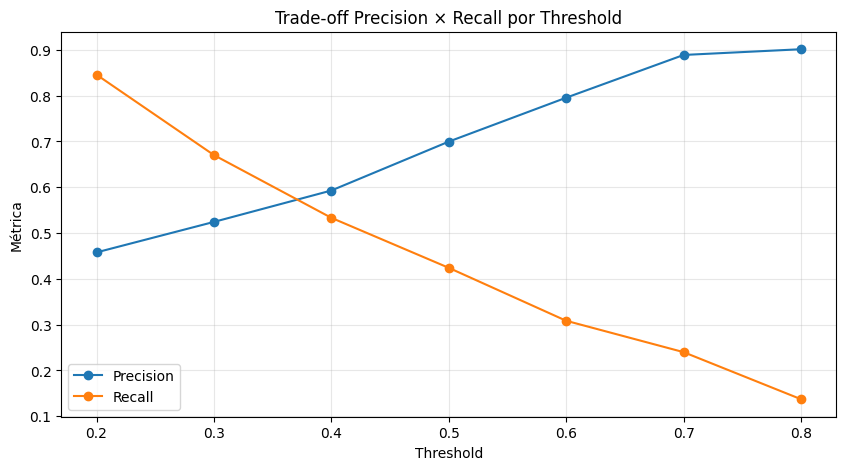

In [117]:
plt.figure(figsize=(10, 5))

plt.plot(
    comparacao_negocio["threshold"],
    comparacao_negocio["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    comparacao_negocio["threshold"],
    comparacao_negocio["recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title("Trade-off Precision × Recall por Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Dinheiro

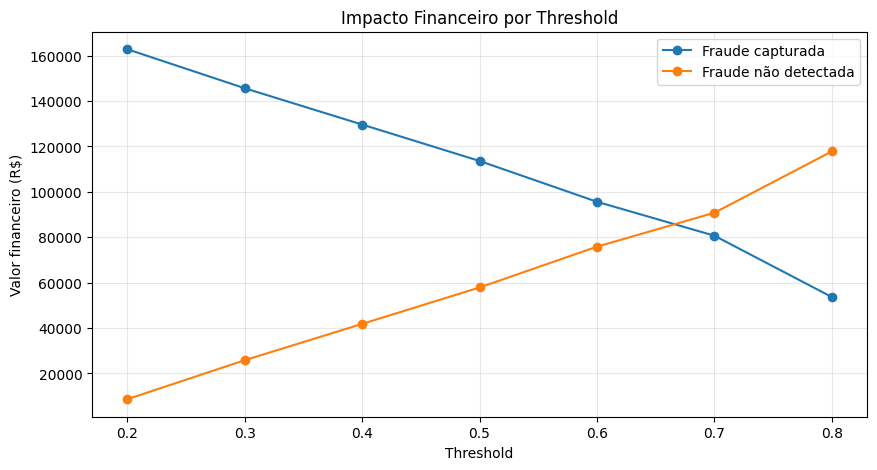

In [118]:
plt.figure(figsize=(10, 5))

plt.plot(
    comparacao_negocio["threshold"],
    comparacao_negocio["fraude_capturada_R$"],
    marker="o",
    label="Fraude capturada"
)

plt.plot(
    comparacao_negocio["threshold"],
    comparacao_negocio["fraude_perdida_R$"],
    marker="o",
    label="Fraude não detectada"
)

plt.xlabel("Threshold")
plt.ylabel("Valor financeiro (R$)")
plt.title("Impacto Financeiro por Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# modelo → score → threshold → fraude capturada → falso positivo → impacto financeiro → política de risco.

Alexandre Lotti
<!LOTTI>